# AutoSplice · CocoGlide 근접 중복 검사

- 작성자: seonghun
- 상태: **완료 — Colab 저장 출력 검토 완료 (2026-11-23), T05 분할 확정은 별도 진행**
- 작성일: 2026-11-19
- 관련 작업: T05 데이터셋 EDA·분할 확정
- [보고서](../../docs/eda/EXP_seonghun_001_near_duplicate_check.md) · [기준 EDA 보고서](../../docs/eda/EXP_kimjaehak_002_dataset_eda.md)

002는 파일 바이트·디코드 RGB가 완전히 같은 중복만 검사했음(0개). 이 노트북은 원본 ID가 다른데 크기·압축 등만 다른 사실상 같은 사진이 다른 split이나 다른 데이터셋에 들어갔는지 확인함.

대상은 AutoSplice 정상 원본 2,273장과 CocoGlide 정상 512장임. AutoSplice 조작본은 같은 원본 ID로 묶여 같은 split에 있으므로 제외함. 이미지마다 64비트 perceptual hash(pHash·dHash)를 계산하고, 서로 다른 split·데이터셋 사이의 가까운 쌍을 후보로 뽑아 사람이 판단함.

perceptual hash는 크롭·큰 편집·좌우반전에 약하므로 후보가 0개여도 누수가 없다고 결론내리지 않음. 거리 기준값은 검토 후보를 고르는 용도이며 학습 설정이 아님. test와 CocoGlide는 중복 검사에만 사용함. 분할 CSV를 자동으로 수정하지 않음.

팀원이 VS Code의 Colab 원격 커널에서 위에서부터 실행하고 출력이 포함된 노트북을 저장함. 보고서는 저장된 출력으로 작성함.

## 1. Drive·공통 코드·실행 환경 준비

공유 Drive의 `AI_Forensics/datasets/AutoSplice/AutoSplice.zip`, `AI_Forensics/datasets/CocoGlide.zip`과 `AI_Forensics/project/scripts/`를 사용함. 새 커널에서 시작함. 실제 import 위치와 코드·분할 해시를 확인하고 002에서 검토한 버전과 다르면 중단함. 기대 해시만 바꿔 통과시키지 않음.

GPU는 사용하지 않음. 아래 버전은 실행 기록이며 팀 표준을 확정하는 셀이 아님.

In [1]:
from pathlib import Path
from google.colab import drive
import importlib
import importlib.metadata
import platform
import sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, features
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
drive.mount("/content/drive")
shared_root = Path("/content/drive/MyDrive/AI_Forensics")
project_root = shared_root / "project"
work_root = Path("/content")
data_root = work_root / "datasets"
split_path = project_root / "scripts/splits/autosplice_seed42.csv"
archive_paths = {
    "AutoSplice": shared_root / "datasets/AutoSplice/AutoSplice.zip",
    "CocoGlide": shared_root / "datasets/CocoGlide.zip",
}
extract_paths = {"AutoSplice": data_root, "CocoGlide": data_root / "CocoGlide"}
required = ["scripts/__init__.py", "scripts/datasets.py", "scripts/preprocessing.py", "scripts/splits/autosplice_seed42.csv"]
for relative in required:
    if not (project_root / relative).is_file():
        raise FileNotFoundError(f"Drive에 공통 파일을 업로드해야 함: {relative}")

sys.path.insert(0, str(project_root))
importlib.invalidate_caches()
import scripts
import scripts.datasets as dataset_module
import scripts.preprocessing as preprocessing_module

for module, relative in [(scripts, "scripts/__init__.py"), (dataset_module, "scripts/datasets.py"),
                         (preprocessing_module, "scripts/preprocessing.py")]:
    if Path(module.__file__).resolve() != (project_root / relative).resolve():
        raise ImportError(f"프로젝트의 모듈을 불러오도록 커널을 재시작해야 함: {relative}")
    print("불러온 코드:", module.__file__)

from scripts.datasets import sha256, prepare_dataset_zip, autosplice_records, cocoglide_records
from scripts.preprocessing import load_rgb

print("실행 시각 UTC:", datetime.now(timezone.utc).isoformat())
print("Python:", platform.python_version())
print("OS:", platform.platform())
for package in ("numpy", "Pillow", "pandas", "matplotlib"):
    print(package, importlib.metadata.version(package))
print("JPEG library:", features.version("jpg"))
print("GPU: 사용하지 않음")
print("프로젝트:", project_root)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/__init__.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/datasets.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/preprocessing.py
실행 시각 UTC: 2026-11-19T07:10:19.587699+00:00
Python: 3.13.16
OS: Linux-6.6.159+-x86_64-with-glibc2.39
numpy 2.4.6
Pillow 11.3.0
pandas 2.2.3
matplotlib 3.10.0
JPEG library: 6.2
GPU: 사용하지 않음
프로젝트: /content/drive/MyDrive/AI_Forensics/project


In [2]:
expected_files = {
    "scripts/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855",
    "scripts/datasets.py": "435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88",
    "scripts/preprocessing.py": "69809276be12200a3cd2ef1e96364a7d168b39cae0a2cce1946f84d7ce74db07",
    "scripts/splits/autosplice_seed42.csv": "f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e",
}
for relative, expected_hash in expected_files.items():
    actual_hash = sha256(project_root / relative)
    print(relative, actual_hash)
    if actual_hash != expected_hash:
        raise ValueError(f"검토한 코드·분할 버전과 일치해야 함: {relative}")

hash_size = 8
dct_size = 32
candidate_threshold = 10
review_top_k = 20
plot_limit = 40
table_limit = 200
settings = dict(hash_size=hash_size, dct_size=dct_size, candidate_threshold=candidate_threshold, review_top_k=review_top_k,
                plot_limit=plot_limit, table_limit=table_limit)
print("검사 설정:", settings)
print("candidate_threshold는 64비트 해밍 거리의 검토 후보 기준이며 학습 설정이 아님")

scripts/__init__.py e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
scripts/datasets.py 435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88
scripts/preprocessing.py 69809276be12200a3cd2ef1e96364a7d168b39cae0a2cce1946f84d7ce74db07
scripts/splits/autosplice_seed42.csv f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e
검사 설정: {'hash_size': 8, 'dct_size': 32, 'candidate_threshold': 10, 'review_top_k': 20, 'plot_limit': 40, 'table_limit': 200}
candidate_threshold는 64비트 해밍 거리의 검토 후보 기준이며 학습 설정이 아님


## 2. 데이터 ZIP 준비

001·002와 같은 ZIP·공통 함수를 사용함. AutoSplice는 datasets에, CocoGlide는 datasets/CocoGlide에 해제함. 기존 완료 표시가 있으면 해제 파일을 재사용하며 그 여부를 출력으로 남김.

In [3]:
archive_hashes = {
    "AutoSplice": "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36",
    "CocoGlide": "fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9",
}
for name, source in archive_paths.items():
    prepare_dataset_zip(source, work_root / f"{name}.zip", extract_paths[name], archive_hashes[name])
    print(name, "ZIP SHA-256:", archive_hashes[name])

AutoSplice 기존 해제 파일 사용
AutoSplice ZIP SHA-256: 0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36
CocoGlide ZIP SHA-256 확인 및 압축 해제 완료
CocoGlide ZIP SHA-256: fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9


## 3. 검사 대상 목록

AutoSplice는 고정 분할 CSV로 원본 ID별 split을 연결한 정상 원본, CocoGlide는 table.csv의 정상 이미지를 사용함. 비교 그룹은 AutoSplice train·val·test와 CocoGlide external_test임.

In [4]:
auto = [row for row in autosplice_records(data_root / "AutoSplice", split_path, quality=100) if row["kind"] == "normal"]
coco = [row for row in cocoglide_records(data_root / "CocoGlide") if row["kind"] == "normal"]
targets = pd.DataFrame(auto + coco)
targets["group"] = np.where(targets["dataset"] == "AutoSplice", "AutoSplice_" + targets["split"], "CocoGlide")
counts = targets.groupby("group").size().to_dict()
print("대상 수:", counts)
expected_counts = {"AutoSplice_train": 1818, "AutoSplice_val": 227, "AutoSplice_test": 228, "CocoGlide": 512}
if counts != expected_counts:
    raise ValueError("002에서 확인한 대상 수와 일치해야 함.")
if targets["image_path"].duplicated().any():
    raise ValueError("대상 이미지 경로는 중복되지 않아야 함.")

대상 수: {'AutoSplice_test': 228, 'AutoSplice_train': 1818, 'AutoSplice_val': 227, 'CocoGlide': 512}


## 4. perceptual hash 계산

공통 함수 `load_rgb`로 읽고 Pillow로 회색조 변환 후 두 가지 64비트 해시를 계산함.

- dHash: 9×8로 축소하고 가로로 인접한 픽셀의 밝기 크기를 비교함.
- pHash: 32×32로 축소해 2차원 DCT를 구하고 저주파 8×8 계수를 중앙값과 비교함.

축소에는 Pillow의 LANCZOS를 사용함. 두 해시 모두 리사이즈·재압축에는 강하지만 크롭·회전·좌우반전·큰 편집에는 약함.

In [5]:
def dct_matrix(size):
    k = np.arange(size)[:, None]
    n = np.arange(size)[None, :]
    matrix = np.cos(np.pi * (2 * n + 1) * k / (2 * size)) * np.sqrt(2 / size)
    matrix[0] /= np.sqrt(2)
    return matrix


DCT = dct_matrix(dct_size)


def image_hashes(rgb):
    gray = Image.fromarray(rgb).convert("L")
    small = np.asarray(gray.resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS), dtype=np.float64)
    dhash = (small[:, 1:] > small[:, :-1]).ravel()
    pixels = np.asarray(gray.resize((dct_size, dct_size), Image.Resampling.LANCZOS), dtype=np.float64)
    low = (DCT @ pixels @ DCT.T)[:hash_size, :hash_size].ravel()
    phash = low > np.median(low[1:])
    return phash, dhash


phash_bits, dhash_bits, sizes, hash_errors = [], [], [], []
for row in targets.itertuples():
    try:
        rgb = load_rgb(row.image_path)
        phash, dhash = image_hashes(rgb)
        phash_bits.append(phash)
        dhash_bits.append(dhash)
        sizes.append(f"{rgb.shape[0]}x{rgb.shape[1]}")
    except Exception as error:
        hash_errors.append(dict(image=str(row.image_path), error=repr(error)))

print("해시 계산:", len(phash_bits), "/ 오류:", len(hash_errors))
if hash_errors:
    display(pd.DataFrame(hash_errors))
    raise RuntimeError("읽기 오류를 확인한 뒤 다음 단계로 진행해야 함.")
targets["size"] = sizes
phash_bits = np.array(phash_bits, dtype=np.int32)
dhash_bits = np.array(dhash_bits, dtype=np.int32)
print("pHash 비트 1의 평균 비율:", round(float(phash_bits.mean()), 4), "/ dHash:", round(float(dhash_bits.mean()), 4))

해시 계산: 2785 / 오류: 0
pHash 비트 1의 평균 비율: 0.5 / dHash: 0.4857


## 5. 그룹 간 거리와 후보

모든 쌍의 해밍 거리를 비트 행렬곱으로 계산함. 서로 다른 그룹 사이의 쌍만 누수 후보로 봄. 같은 그룹 안의 가까운 쌍은 같은 split에 있으므로 누수가 아니며 참고 개수만 출력함.

pHash·dHash 중 하나라도 기준값 이하이면 후보로 표시함. 각 이미지에서 다른 그룹의 가장 가까운 이미지까지의 pHash 거리 분포도 함께 그림. 기준값 부근에 따로 떨어진 무리가 있는지 확인함.

그룹 간 후보 쌍: 34


,group_a,group_b,kind,pairs,candidates,min_phash
0,AutoSplice_train,AutoSplice_train,같은 그룹(참고),1651653,45,0
1,AutoSplice_train,AutoSplice_val,그룹 간,412686,16,0
2,AutoSplice_train,AutoSplice_test,그룹 간,414504,13,12
3,AutoSplice_train,CocoGlide,그룹 간,930816,2,12
4,AutoSplice_val,AutoSplice_val,같은 그룹(참고),25651,1,14
5,AutoSplice_val,AutoSplice_test,그룹 간,51756,2,12
6,AutoSplice_val,CocoGlide,그룹 간,116224,1,14
7,AutoSplice_test,AutoSplice_test,같은 그룹(참고),25878,1,16
8,AutoSplice_test,CocoGlide,그룹 간,116736,0,12
9,CocoGlide,CocoGlide,같은 그룹(참고),130816,1,14


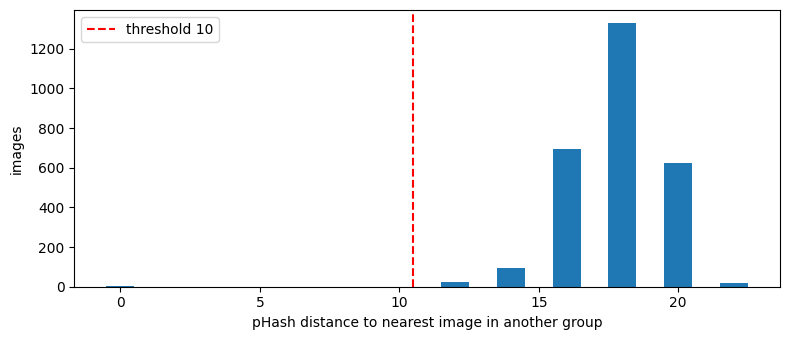

다른 그룹 최근접 pHash 거리 요약:


,count,mean,std,min,25%,50%,75%,max
nearest_phash,2785.0,17.77,1.74,0.0,16.0,18.0,18.0,22.0


In [6]:
def hamming(bits):
    return bits @ (1 - bits).T + (1 - bits) @ bits.T


phash_dist = hamming(phash_bits)
dhash_dist = hamming(dhash_bits)
groups = targets["group"].to_numpy()
upper = np.triu(np.ones(phash_dist.shape, dtype=bool), k=1)
cross = groups[:, None] != groups[None, :]

pair_rows = []
for i, j in zip(*np.nonzero(upper & cross & ((phash_dist <= candidate_threshold) | (dhash_dist <= candidate_threshold)))):
    pair_rows.append(dict(i=i, j=j, phash=int(phash_dist[i, j]), dhash=int(dhash_dist[i, j])))
candidates = pd.DataFrame(pair_rows, columns=["i", "j", "phash", "dhash"])

summary_rows = []
names = list(expected_counts)
for a_index, a in enumerate(names):
    for b in names[a_index:]:
        mask = upper & (groups[:, None] == a) & (groups[None, :] == b) if a == b else \
               ((groups[:, None] == a) & (groups[None, :] == b))
        close = mask & ((phash_dist <= candidate_threshold) | (dhash_dist <= candidate_threshold))
        summary_rows.append(dict(group_a=a, group_b=b, kind="같은 그룹(참고)" if a == b else "그룹 간",
                                 pairs=int(mask.sum()), candidates=int(close.sum()),
                                 min_phash=int(phash_dist[mask].min()) if mask.any() else None))
print("그룹 간 후보 쌍:", len(candidates))
display(pd.DataFrame(summary_rows))

nearest = np.where(cross, phash_dist, 999).min(axis=1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(nearest, bins=np.arange(0, nearest.max() + 2) - 0.5)
ax.axvline(candidate_threshold + 0.5, color="red", linestyle="--", label=f"threshold {candidate_threshold}")
ax.set_xlabel("pHash distance to nearest image in another group")
ax.set_ylabel("images")
ax.legend()
plt.tight_layout()
plt.show()
print("다른 그룹 최근접 pHash 거리 요약:")
display(pd.Series(nearest).describe().round(2).to_frame("nearest_phash").T)

## 6. 사람 검토용 쌍

기준값 이하 후보 전부와, 기준값과 상관없이 그룹 간 pHash 거리가 가장 가까운 상위 쌍을 함께 보여줌. 두 거리 중 작은 값 순으로 정렬함. 기준값만으로 판단하지 않고 그림으로 같은 사진인지 확인함. 같은 장면이라도 다른 사진이면 중복으로 보지 않음.

검토 쌍: 53 / 그중 기준값 이하 후보: 34


,phash,dhash,min_distance,candidate,i_group,i_id,i_file,i_size,j_group,j_id,j_file,j_size
0,0,0,0,True,AutoSplice_train,46217,46217.jpg,256x360,AutoSplice_val,54313,54313.jpg,256x360
1,22,7,7,True,AutoSplice_train,54467,54467.jpg,256x365,AutoSplice_val,54769,54769.jpg,256x363
2,22,8,8,True,AutoSplice_train,60912,60912.jpg,256x281,AutoSplice_val,65777,65777.jpg,256x396
3,24,8,8,True,AutoSplice_train,40468,40468.jpg,256x352,AutoSplice_val,43331,43331.jpg,256x358
4,24,8,8,True,AutoSplice_val,43572,43572.jpg,256x408,AutoSplice_train,65564,65564.jpg,256x339
5,24,8,8,True,AutoSplice_train,51199,51199.jpg,325x256,AutoSplice_test,56407,56407.jpg,292x256
6,30,8,8,True,AutoSplice_train,42407,42407.jpg,256x386,AutoSplice_test,45749,45749.jpg,256x388
7,24,9,9,True,AutoSplice_val,44881,44881.jpg,256x384,AutoSplice_train,57204,57204.jpg,256x384
8,26,9,9,True,AutoSplice_test,53834,53834.jpg,256x383,AutoSplice_train,66904,66904.jpg,256x384
9,26,9,9,True,AutoSplice_val,54411,54411.jpg,256x384,AutoSplice_test,72825,72825.jpg,256x384


그림은 거리 순 상위 40쌍만 표시함. 나머지는 위 표에서 확인해야 함





In [7]:
cross_upper = upper & cross
order = np.argsort(phash_dist[cross_upper], kind="stable")[:review_top_k]
top_i, top_j = np.nonzero(cross_upper)
top = pd.DataFrame(dict(i=top_i[order], j=top_j[order]))
top["phash"] = phash_dist[top["i"], top["j"]]
top["dhash"] = dhash_dist[top["i"], top["j"]]
review = pd.concat([candidates, top], ignore_index=True).drop_duplicates(["i", "j"])
review["min_distance"] = review[["phash", "dhash"]].min(axis=1)
review = review.sort_values(["min_distance", "phash", "dhash", "i", "j"]).reset_index(drop=True)
review["candidate"] = (review["phash"] <= candidate_threshold) | (review["dhash"] <= candidate_threshold)
for side in ("i", "j"):
    info = targets.iloc[review[side]].reset_index(drop=True)
    review[f"{side}_group"] = info["group"]
    review[f"{side}_id"] = info["original_id"]
    review[f"{side}_file"] = info["image_path"].map(lambda p: p.name)
    review[f"{side}_size"] = info["size"]
print("검토 쌍:", len(review), "/ 그중 기준값 이하 후보:", int(review["candidate"].sum()))
if len(review) > table_limit:
    print(f"표는 거리 순 상위 {table_limit}쌍만 표시함")
display(review.drop(columns=["i", "j"]).head(table_limit))

shown = review.head(plot_limit)
if len(review) > plot_limit:
    print(f"그림은 거리 순 상위 {plot_limit}쌍만 표시함. 나머지는 위 표에서 확인해야 함")
fig, axes = plt.subplots(len(shown), 2, figsize=(8, 3.2 * len(shown)), squeeze=False)
for axes_row, pair in zip(axes, shown.itertuples()):
    for ax, side in zip(axes_row, ("i", "j")):
        row = targets.iloc[getattr(pair, side)]
        ax.imshow(load_rgb(row["image_path"]))
        ax.set_title(f"{row['group']} / {row['image_path'].name}\npHash {pair.phash} dHash {pair.dhash}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

## 7. 결과 정리

자동 검사 결과를 요약함. 후보가 같은 사진으로 확인되면 분할 변경 여부를 팀이 합의해야 하며 CSV를 자동으로 다시 만들지 않음. 팀원은 6절 그림을 확인하고 아래 검토 메모를 채운 뒤 출력이 포함된 파일을 저장함.

In [8]:
result_summary = {
    "대상 수": counts,
    "해시 읽기 오류": len(hash_errors),
    "그룹 간 기준값 이하 후보 쌍": len(candidates),
    "검토용 표시 쌍": len(review),
    "다른 그룹 최근접 pHash 거리 최솟값": int(nearest.min()),
}
for key, value in result_summary.items():
    print(f"{key}: {value}")

대상 수: {'AutoSplice_test': 228, 'AutoSplice_train': 1818, 'AutoSplice_val': 227, 'CocoGlide': 512}
해시 읽기 오류: 0
그룹 간 기준값 이하 후보 쌍: 34
검토용 표시 쌍: 53
다른 그룹 최근접 pHash 거리 최솟값: 0


### 사람의 검토 메모

- 6절 쌍 중 같은 사진으로 판단한 쌍(ID·그룹·이유): 미확인
- 분할 변경 필요 여부: 미정 — 팀 합의 필요
- 근접 중복 검사의 한계(크롭·반전·큰 편집 미검출)에 대한 판단: 미확인
- T05 완료 여부: 결과 검토 전

[개별 보고서](../../docs/eda/EXP_seonghun_001_near_duplicate_check.md) · [EDA 목록](../../docs/results.md) · [TODO](../../TODO.md)